# Dynamic rotation with $\dot{\mathbf j}$ kept: prototype solver examples

Examples for the solver in `rotation_jdot.py`, which implements the algorithm of
`notes/rotation_jdot.pdf` §6 (trapezoid step on $\boldsymbol\ell = I_1\boldsymbol\omega+\mathbf j+\mathbf h$,
inner sea-level iteration). Elastic Earth, hydrostatic ocean, no core, no damping; equatorial rotation only.

Each check prints the simulated number next to the analytic one. The reduced model
($\mathbf j=\mathbf j^\zeta+(I_3-I_1)\mathsf K\boldsymbol\omega$) and the formulas are in `rotation_jdot_checks.py`.

Sidereal $\Omega$ is used, so numbers differ slightly from the note's §8 tables (solar $\Omega$).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from pyslfp import SeaLevelEquation

import rotation_jdot as rj
import rotation_jdot_checks as rc

/space/dah94/rotation/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 0. Parameters, Earth model and constants

In [2]:
#=======================================================================
# Parameters
#=======================================================================

lmax = 64
rtol = 1e-10
year = 365.25

# Size of the initial free wobble (pole offset, mas)
wobble_mas = 100.0

# Fraction of Northern Hemisphere ice used for the hemispheric loads
nh_fraction = 1e-3

In [3]:
#=======================================================================
# Earth model, constants and feedback matrices
#=======================================================================

state = rj.make_state(lmax)
constants = rj.rotation_constants(state.model)
model = state.model

# Feedback matrices: solid Earth only (kappa 1) and with the ocean pole tide
k_no_ocean = rc.feedback_matrix(state, constants, ocean=False)
k_ocean = rc.feedback_matrix(state, constants, ocean=True)

# Free-wobble periods with j-dot kept
sigma_cw_no_ocean = rc.chandler_frequency(constants, k_no_ocean)
sigma_cw_ocean = rc.chandler_frequency(constants, k_ocean)
t_e = 2 * np.pi / rc.per_day(constants["sigma_e"], constants)
t_cw_no_ocean = 2 * np.pi / rc.per_day(sigma_cw_no_ocean, constants)
t_cw_ocean = 2 * np.pi / rc.per_day(sigma_cw_ocean, constants)

print(f"Omega = {constants['omega'] / constants['time_scale']:.7e} rad/s (sidereal)")
print(f"kappa = {constants['kappa']:.5f},  B / I1 = {constants['b_inertia'] / constants['i1']:.3e}")
print(f"K (ocean) =\n{k_ocean}\n  asymmetry {abs(k_ocean[0, 1] - k_ocean[1, 0]):.1e}")
print(f"T_e = {t_e:.2f} d")
print(f"T_CW (j-dot kept): no ocean {t_cw_no_ocean:.2f} d, ocean {t_cw_ocean:.2f} d")
print(f"   note §8 (solar Omega):     444.48 d,        476.60 d")

Omega = 7.2921150e-05 rad/s (sidereal)
kappa = 0.31562,  B / I1 = 1.036e-03
K (ocean) =
[[ 0.36742332 -0.00120718]
 [-0.00120718  0.35684598]]
  asymmetry 6.5e-19
T_e = 303.72 d
T_CW (j-dot kept): no ocean 444.24 d, ocean 476.73 d
   note §8 (solar Omega):     444.48 d,        476.60 d


In [4]:
#=======================================================================
# Loads used below
#=======================================================================

# Degree-2, order-1 loads (cosine and sine), scaled to a pole shift of order 100 mas
y21c_unit = rj.harmonic_load(model, 2, 1)
static_unit = rj.solve_step(state, constants, y21c_unit, mode="static", ocean=False)
y21_amplitude = wobble_mas / rj.omega_to_mas(static_unit["omega"][0], constants)
y21c_load = rj.harmonic_load(model, 2, 1, amplitude=y21_amplitude)
y21s_load = rj.harmonic_load(model, 2, 1, sine=True, amplitude=y21_amplitude)

# Hemispheric load: melt a small fraction of Northern Hemisphere ice
nh_load = state.northern_hemisphere_load(fraction=nh_fraction)
zero_load = model.zero_grid()

# Initial wobble giving a 100 mas pole offset
omega_wobble = np.array([wobble_mas / rj.omega_to_mas(1.0, constants), 0.0])

## 1. Free wobble

Start with a prescribed $\boldsymbol\omega_0$ (pole offset 100 mas) and no load. The period should match
$\sigma'_{\rm CW}$ (§4.3). The discrete trapezoid step lengthens it slightly. That discrete value comes from the
eigenvalues of the one-step map, and the run should reproduce it to rounding.

In [5]:
#=======================================================================
# Free wobble, with and without the ocean
#=======================================================================

dt_free = 1.0
nt_free = int(3 * year / dt_free) + 1

start_time = time.time()
free_no_ocean = rj.march(
    state,
    constants,
    None,
    dt_free,
    nt_free,
    start="rest",
    omega_0=omega_wobble,
    ocean=False,
    rtol=rtol,
)
free_ocean = rj.march(
    state,
    constants,
    None,
    dt_free,
    nt_free,
    start="rest",
    omega_0=omega_wobble,
    ocean=True,
    rtol=rtol,
)
print(f"Runs took {time.time() - start_time:.1f} s; mean iterations per step (ocean) "
      f"{free_ocean['iterations'][1:].mean():.1f}")

for label, run, k_mat in [
    ("no ocean", free_no_ocean, k_no_ocean),
    ("ocean", free_ocean, k_ocean),
]:
    period = rc.wobble_period_days(run["t_days"], run["omega"])
    sigma_discrete = rc.discrete_chandler_frequency(constants, k_mat, dt_free)
    period_discrete = 2 * np.pi / rc.per_day(sigma_discrete, constants)
    period_exact = 2 * np.pi / rc.per_day(rc.chandler_frequency(constants, k_mat), constants)
    # The free motion is an ellipse when K is anisotropic; the reduced model gives its shape
    reduced = rc.march_reduced(constants, k_mat, np.zeros((nt_free, 2)), dt_free, omega_0=omega_wobble)
    amplitude = np.linalg.norm(run["omega"], axis=1)
    amplitude_reduced = np.linalg.norm(reduced["omega"], axis=1)
    print(f"{label:9s}: period simulated {period:.4f} d, discrete step {period_discrete:.4f} d, "
          f"continuous {period_exact:.4f} d")
    print(f"           |omega| max/min {amplitude.max() / amplitude.min():.6f} "
          f"(reduced model {amplitude_reduced.max() / amplitude_reduced.min():.6f}); "
          f"|omega| at end / start {amplitude[-1] / amplitude[0]:.6f} "
          f"(reduced {amplitude_reduced[-1] / amplitude_reduced[0]:.6f})")

Runs took 26.3 s; mean iterations per step (ocean) 12.3
no ocean : period simulated 444.2503 d, discrete step 444.2503 d, continuous 444.2429 d
           |omega| max/min 1.000000 (reduced model 1.000000); |omega| at end / start 1.000000 (reduced 1.000000)
ocean    : period simulated 476.7347 d, discrete step 476.7347 d, continuous 476.7278 d
           |omega| max/min 1.008523 (reduced model 1.008523); |omega| at end / start 0.992989 (reduced 0.992989)


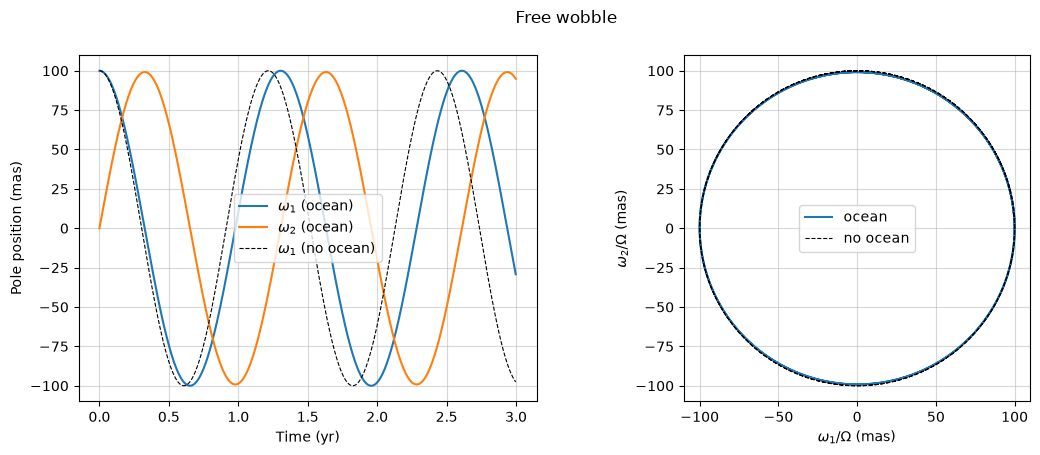

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

pole_ocean = rj.omega_to_mas(free_ocean["omega"], constants)
pole_no_ocean = rj.omega_to_mas(free_no_ocean["omega"], constants)

axes[0].plot(free_ocean["t_days"] / year, pole_ocean[:, 0], label=r"$\omega_1$ (ocean)")
axes[0].plot(free_ocean["t_days"] / year, pole_ocean[:, 1], label=r"$\omega_2$ (ocean)")
axes[0].plot(free_no_ocean["t_days"] / year, pole_no_ocean[:, 0], "k--", lw=0.8, label=r"$\omega_1$ (no ocean)")
axes[0].set_xlabel("Time (yr)")
axes[0].set_ylabel("Pole position (mas)")
axes[0].legend()
axes[0].grid(True, alpha=0.5)

axes[1].plot(pole_ocean[:, 0], pole_ocean[:, 1], label="ocean")
axes[1].plot(pole_no_ocean[:, 0], pole_no_ocean[:, 1], "k--", lw=0.8, label="no ocean")
axes[1].set_xlabel(r"$\omega_1/\Omega$ (mas)")
axes[1].set_ylabel(r"$\omega_2/\Omega$ (mas)")
axes[1].set_aspect("equal")
axes[1].legend()
axes[1].grid(True, alpha=0.5)

fig.suptitle("Free wobble")
plt.show()

## 2. Literal algorithm vs closed-form alternative

The default rotation update is the §6 box: $\boldsymbol\omega^{(k+1)}=\mathsf P^{-1}(\mathbf b_n-\mathsf C\mathbf j^{(k)})$.
The alternative (`closed_form=True`) solves the solid-Earth part exactly, $(\mathsf P+\mathsf C B)\boldsymbol\omega=\mathbf b_n-\mathsf C\mathsf A\sigma$,
as pyslfp's static solver does. Both should give the same answer to solver tolerance.

In [7]:
dt_compare = 7.0
nt_compare = 60
nh_annual = lambda t: np.sin(2 * np.pi * t / year) * nh_load

literal = rj.march(state, constants, nh_annual, dt_compare, nt_compare, rtol=rtol)
closed = rj.march(state, constants, nh_annual, dt_compare, nt_compare, closed_form=True, rtol=rtol)

difference = np.abs(literal["omega"] - closed["omega"]).max() / np.abs(literal["omega"]).max()
print(f"max |omega_literal - omega_closed| / max |omega| = {difference:.2e}")
print(f"mean iterations per step: literal {literal['iterations'][1:].mean():.1f}, "
      f"closed form {closed['iterations'][1:].mean():.1f}")

max |omega_literal - omega_closed| / max |omega| = 5.39e-11
mean iterations per step: literal 13.4, closed form 13.4


## 3. Static limit

(a) Starting from equilibrium (§7) with a constant load, nothing should move.
(b) The static solve used for that start agrees with pyslfp's static solver up to the axial rotation $\omega_3$.
pyslfp 2.2.0 includes $\omega_3$, and this prototype omits it.
(c) For a slow ramp from rest, $\boldsymbol\omega$ follows the static answer. It is offset sideways by
$|\dot{\boldsymbol\omega}_s|/\sigma_{\rm CW}$ (N eq. 25), plus a free wobble of the same size.

In [8]:
#=======================================================================
# (a) Constant load from equilibrium
#=======================================================================

constant_nh = lambda t: nh_load
equilibrium = rj.march(
    state,
    constants,
    constant_nh,
    7.0,
    105,
    start="equilibrium",
    rtol=rtol,
)
drift = np.abs(equilibrium["omega"] - equilibrium["omega"][0]).max() / np.abs(equilibrium["omega"][0]).max()
print(f"(a) max drift of omega over 2 yr from equilibrium, relative: {drift:.2e}")
print(f"    |T_0| / |Omega j_0| = {np.linalg.norm(equilibrium['torque'][0]) / (constants['omega'] * np.linalg.norm(equilibrium['j'][0])):.2e}")

#=======================================================================
# (b) Static solve vs pyslfp's static solver
#=======================================================================

sle = SeaLevelEquation(model)
slc_pyslfp, _, _, omega_pyslfp = sle.solve_sea_level_equation(state, nh_load, rtol=1e-12)
static_nh = rj.solve_step(state, constants, nh_load, mode="static", rtol=1e-12)
omega_difference = np.linalg.norm(static_nh["omega"] - omega_pyslfp[:2]) / np.linalg.norm(omega_pyslfp[:2])
slc_difference = np.abs(static_nh["sea_level"].data - slc_pyslfp.data).max() / np.abs(slc_pyslfp.data).max()
print(f"(b) static omega: prototype {static_nh['omega']}, pyslfp {omega_pyslfp}")
print(f"    relative differences: omega {omega_difference:.1e}, sea level {slc_difference:.1e} (pyslfp includes omega_3)")

(a) max drift of omega over 2 yr from equilibrium, relative: 6.48e-11
    |T_0| / |Omega j_0| = 0.00e+00
(b) static omega: prototype [ 6.57409971e-09 -4.94537837e-09], pyslfp [ 6.57404716e-09 -4.94537366e-09 -3.80842927e-11]
    relative differences: omega 6.4e-06, sea level 5.9e-05 (pyslfp includes omega_3)


(c) max |omega - omega_static| = 1.706e-10; predicted offset 8.544e-11 (the deviation is at most twice this: offset + free wobble)
    relative to the final static omega: 2.07e-02


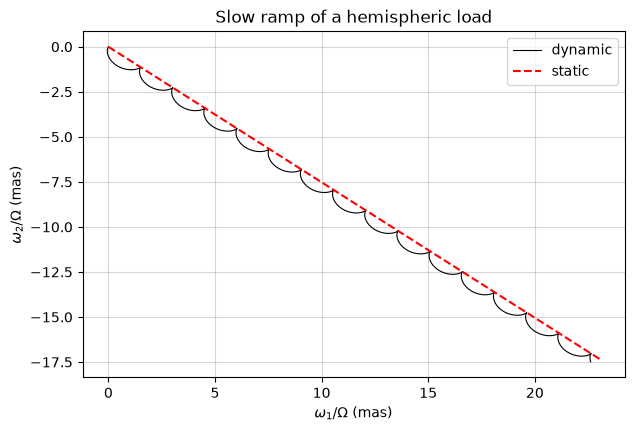

In [9]:
#=======================================================================
# (c) Slow ramp from rest
#=======================================================================

ramp_years = 20.0
dt_ramp = 10.0
nt_ramp = int(ramp_years * year / dt_ramp) + 1
ramp_nh = lambda t: (t / (ramp_years * year)) * nh_load

ramp = rj.march(state, constants, ramp_nh, dt_ramp, nt_ramp, rtol=rtol)
omega_static_ramp = np.outer(ramp["t_days"] / (ramp_years * year), static_nh["omega"])

# Predicted offset size |d omega_s / dt| / sigma_CW, using rates per day
omega_rate = np.linalg.norm(static_nh["omega"]) / (ramp_years * year)
offset_predicted = omega_rate / rc.per_day(sigma_cw_ocean, constants)
deviation = np.linalg.norm(ramp["omega"] - omega_static_ramp, axis=1)
print(f"(c) max |omega - omega_static| = {deviation.max():.3e}; predicted offset {offset_predicted:.3e} "
      f"(the deviation is at most twice this: offset + free wobble)")
print(f"    relative to the final static omega: {deviation.max() / np.linalg.norm(static_nh['omega']):.2e}")

fig, ax = plt.subplots(figsize=(7, 4.5))
pole_ramp = rj.omega_to_mas(ramp["omega"], constants)
pole_static_ramp = rj.omega_to_mas(omega_static_ramp, constants)
ax.plot(pole_ramp[:, 0], pole_ramp[:, 1], "k", lw=0.8, label="dynamic")
ax.plot(pole_static_ramp[:, 0], pole_static_ramp[:, 1], "r--", label="static")
ax.set_xlabel(r"$\omega_1/\Omega$ (mas)")
ax.set_ylabel(r"$\omega_2/\Omega$ (mas)")
ax.set_title("Slow ramp of a hemispheric load")
ax.legend()
ax.grid(True, alpha=0.5)
plt.show()

## 4. Step load

A $Y_{21}$ load is switched on just after $t=0$, with no ocean. $\boldsymbol\ell$ is continuous, so $\boldsymbol\omega$ jumps by
$-(I_3-I_1)(1-\kappa)/(I_1+B)$ times the eventual static response (§8 test 2), then circles the static answer.

jump / static: simulated -0.00224487, analytic -0.00224487


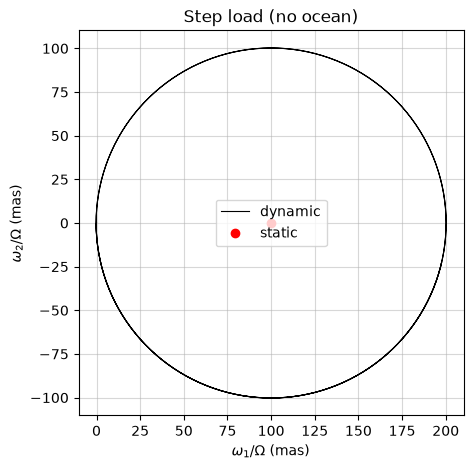

In [10]:
step_on = lambda t: y21c_load if t > 0 else zero_load
static_y21 = rj.solve_step(state, constants, y21c_load, mode="static", ocean=False)

# A tiny first step gives the jump
jump_run = rj.march(state, constants, step_on, 1e-3, 3, ocean=False, rtol=1e-14)
jump_ratio = jump_run["omega"][1, 0] / static_y21["omega"][0]
print(f"jump / static: simulated {jump_ratio:.8f}, analytic {rc.step_jump_ratio(constants):.8f}")

# Then the motion over three years
step_run = rj.march(state, constants, step_on, 1.0, int(3 * year) + 1, ocean=False, rtol=rtol)

fig, ax = plt.subplots(figsize=(5.5, 5))
pole_step = rj.omega_to_mas(step_run["omega"], constants)
pole_static_step = rj.omega_to_mas(static_y21["omega"], constants)
ax.plot(pole_step[:, 0], pole_step[:, 1], "k", lw=0.8, label="dynamic")
ax.plot(*pole_static_step, "ro", label="static")
ax.set_xlabel(r"$\omega_1/\Omega$ (mas)")
ax.set_ylabel(r"$\omega_2/\Omega$ (mas)")
ax.set_aspect("equal")
ax.set_title("Step load (no ocean)")
ax.legend()
ax.grid(True, alpha=0.5)
plt.show()

## 5. Periodic loads and resonance

**(a)** Circular $Y_{21}$ forcing, $\zeta=\cos\nu t\,Y^c_{21}\pm\sin\nu t\,Y^s_{21}$ (+ prograde, − retrograde), with no ocean,
started from equilibrium. The forced part is separated from the free wobble by a least-squares fit. Its ratio to the
static response is compared with $(1+\nu/\Omega)/(1-\nu/\sigma'_{\rm CW})$ (§8 test 3).

In [11]:
#=======================================================================
# (a) Full solver at three forcing periods
#=======================================================================

forcing_periods = [30.0, 182.625, 365.25]
run_years = 4.0
sigma_free_per_day = rc.per_day(sigma_cw_no_ocean, constants)
m_static = static_y21["omega"][0]

full_points = []
start_time = time.time()
for period in forcing_periods:
    for direction in [1, -1]:
        nu_per_day = 2 * np.pi / period
        circular = lambda t: np.cos(nu_per_day * t) * y21c_load + direction * np.sin(nu_per_day * t) * y21s_load
        dt_periodic = period / 120
        nt_periodic = int(run_years * year / dt_periodic) + 1
        run = rj.march(
            state,
            constants,
            circular,
            dt_periodic,
            nt_periodic,
            start="equilibrium",
            ocean=False,
            rtol=1e-12,
        )
        coefficients = rc.fit_forced_response(run["t_days"], run["omega"], nu_per_day, sigma_free_per_day)
        forced = coefficients[0] if direction == 1 else coefficients[1]
        ratio_simulated = (forced / m_static).real
        nu = direction * 2 * np.pi / rj.days_to_model_time(period, constants)
        ratio_analytic = rc.periodic_ratio(constants, nu)
        full_points.append((direction * period, ratio_simulated))
        label = "prograde" if direction == 1 else "retrograde"
        print(f"{period:8.3f} d {label:10s}: simulated {ratio_simulated: .5f}, analytic {ratio_analytic: .5f}, "
              f"rel. diff {abs(ratio_simulated / ratio_analytic - 1):.1e}")
print(f"Runs took {time.time() - start_time:.1f} s")
print("(Near resonance the O(dt^2) step error is amplified, hence the larger difference at 365.25 d prograde.)")

  30.000 d prograde  : simulated -0.07481, analytic -0.07483, rel. diff 2.4e-04


  30.000 d retrograde: simulated  0.06114, analytic  0.06116, rel. diff 2.2e-04


 182.625 d prograde  : simulated -0.70158, analytic -0.70187, rel. diff 4.1e-04


 182.625 d retrograde: simulated  0.28969, analytic  0.28974, rel. diff 1.7e-04


 365.250 d prograde  : simulated -4.62776, analytic -4.63646, rel. diff 1.9e-03


 365.250 d retrograde: simulated  0.44990, analytic  0.44998, rel. diff 1.7e-04
Runs took 19.7 s
(Near resonance the O(dt^2) step error is amplified, hence the larger difference at 365.25 d prograde.)


**(b)** Resonance curve: the analytic ratio against forcing period, with reduced-model runs (fast) and the full-solver points from (a).
The prograde response diverges at $T'_{\rm CW}$. The retrograde response has no resonance.

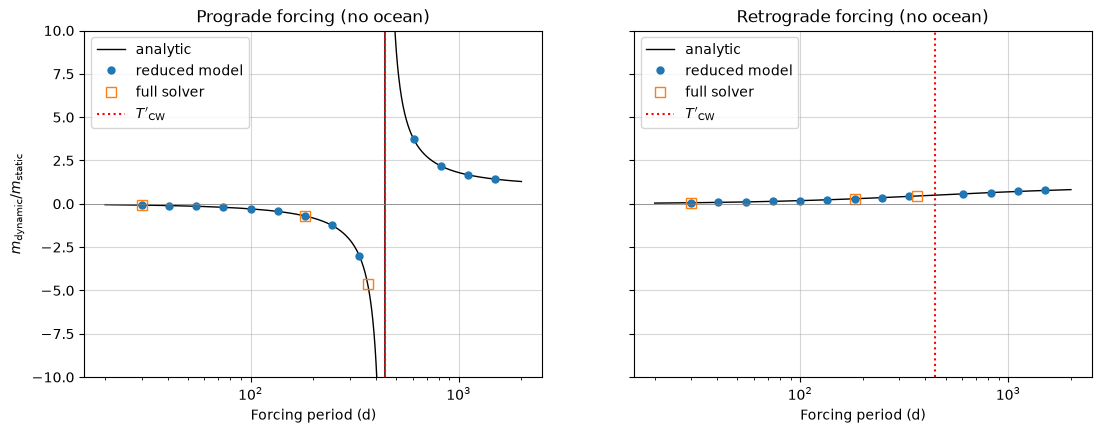

In [12]:
#=======================================================================
# (b) Sweep of forcing period with the reduced model
#=======================================================================

periods_curve = np.geomspace(20, 2000, 800)
nu_curve = 2 * np.pi / rj.days_to_model_time(periods_curve, constants)
ratio_prograde_curve = rc.periodic_ratio(constants, nu_curve)
ratio_retrograde_curve = rc.periodic_ratio(constants, -nu_curve)

# Reduced runs: j^zeta from the static Y21 response, kept away from resonance where the fit is ill-posed
j_static = static_y21["j"][0] * (1 - constants["kappa"])
periods_sweep = np.geomspace(30, 1500, 14)
periods_sweep = periods_sweep[np.abs(periods_sweep / t_cw_no_ocean - 1) > 0.15]
reduced_points = []
for period in periods_sweep:
    for direction in [1, -1]:
        nu_per_day = 2 * np.pi / period
        dt_reduced = min(period / 120, 2.0)
        t_days = np.arange(int(12 * year / dt_reduced) + 1) * dt_reduced
        j_zeta = j_static * np.stack([np.cos(nu_per_day * t_days), direction * np.sin(nu_per_day * t_days)], axis=1)
        omega_0 = j_zeta[0] / (constants["di"] * (1 - constants["kappa"]))
        run = rc.march_reduced(constants, k_no_ocean, j_zeta, dt_reduced, omega_0=omega_0)
        coefficients = rc.fit_forced_response(t_days, run["omega"], nu_per_day, sigma_free_per_day)
        forced = coefficients[0] if direction == 1 else coefficients[1]
        reduced_points.append((direction * period, (forced / omega_0[0]).real))
reduced_points = np.array(reduced_points)
full_points = np.array(full_points)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, direction, curve, title in [
    (axes[0], 1, ratio_prograde_curve, "Prograde"),
    (axes[1], -1, ratio_retrograde_curve, "Retrograde"),
]:
    ax.plot(periods_curve, curve, "k", lw=1, label="analytic")
    reduced = reduced_points[np.sign(reduced_points[:, 0]) == direction]
    full = full_points[np.sign(full_points[:, 0]) == direction]
    ax.plot(np.abs(reduced[:, 0]), reduced[:, 1], "o", color="tab:blue", ms=5, label="reduced model")
    ax.plot(np.abs(full[:, 0]), full[:, 1], "s", color="tab:orange", ms=7, mfc="none", label="full solver")
    ax.axvline(t_cw_no_ocean, color="r", ls=":", label=r"$T'_{\rm CW}$")
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_xscale("log")
    ax.set_ylim(-10, 10)
    ax.set_xlabel("Forcing period (d)")
    ax.set_title(f"{title} forcing (no ocean)")
    ax.grid(True, alpha=0.5)
    ax.legend()
axes[0].set_ylabel(r"$m_{\rm dynamic} / m_{\rm static}$")
plt.show()

**(c)** An annual hemispheric load with the ocean, $\zeta=\sin(2\pi t/1\,{\rm yr})\,\zeta_{\rm NH}$, from rest.
Dynamic and static polar motion are compared, then the sea level at one stored step.

Run took 8.0 s; mean iterations per step 13.3


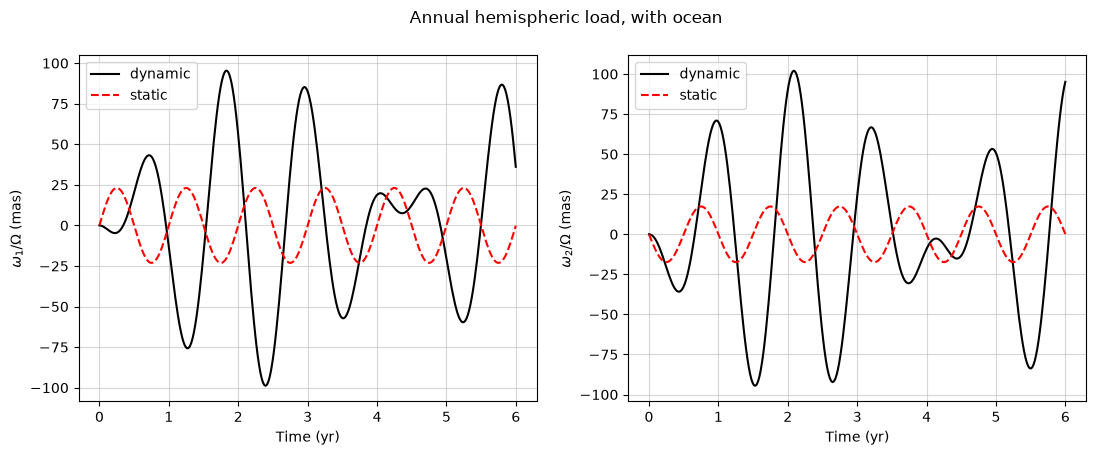

In [13]:
#=======================================================================
# (c) Annual hemispheric load with the ocean
#=======================================================================

dt_annual = 7.0
nt_annual = int(6 * year / dt_annual) + 1
store_steps = [nt_annual - 40]

start_time = time.time()
annual = rj.march(
    state,
    constants,
    nh_annual,
    dt_annual,
    nt_annual,
    store_steps=store_steps,
    rtol=rtol,
)
print(f"Run took {time.time() - start_time:.1f} s; mean iterations per step {annual['iterations'][1:].mean():.1f}")

phase = np.sin(2 * np.pi * annual["t_days"] / year)
omega_static_annual = np.outer(phase, static_nh["omega"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
pole_annual = rj.omega_to_mas(annual["omega"], constants)
pole_static_annual = rj.omega_to_mas(omega_static_annual, constants)
for i, ax in enumerate(axes):
    ax.plot(annual["t_days"] / year, pole_annual[:, i], "k", label="dynamic")
    ax.plot(annual["t_days"] / year, pole_static_annual[:, i], "r--", label="static")
    ax.set_xlabel("Time (yr)")
    ax.set_ylabel(rf"$\omega_{i + 1}/\Omega$ (mas)")
    ax.legend()
    ax.grid(True, alpha=0.5)
fig.suptitle("Annual hemispheric load, with ocean")
plt.show()

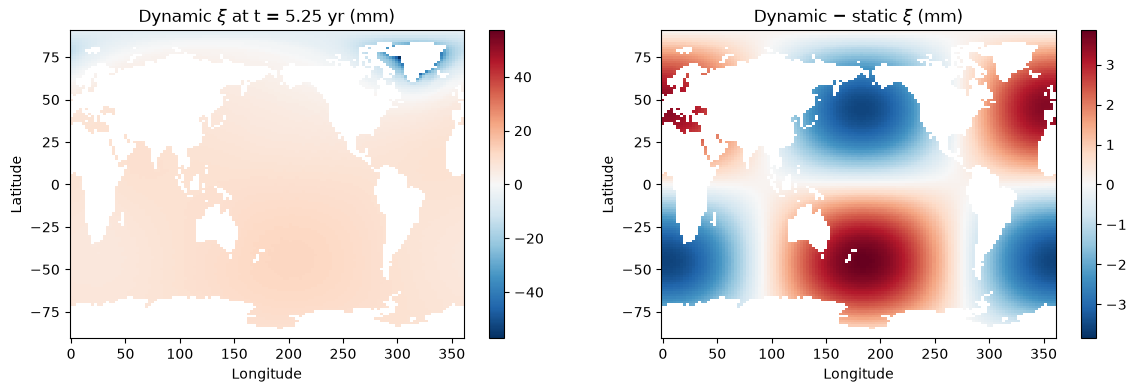

max |dynamic - static| / max |static| over the ocean: 6.62e-02


In [14]:
# Sea level at the stored step: dynamic, and dynamic minus static (mm)
n_map = store_steps[0]
length_scale_mm = model.parameters.length_scale * 1e3
slc_dynamic = annual["sea_level"][n_map].data * length_scale_mm
slc_static = phase[n_map] * static_nh["sea_level"].data * length_scale_mm
ocean_mask = np.where(state.ocean_function.data > 0, 1.0, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, field, title in [
    (axes[0], slc_dynamic * ocean_mask, rf"Dynamic $\xi$ at t = {annual['t_days'][n_map] / year:.2f} yr (mm)"),
    (axes[1], (slc_dynamic - slc_static) * ocean_mask, r"Dynamic $-$ static $\xi$ (mm)"),
]:
    image = ax.pcolormesh(state.lons(), state.lats(), field, cmap="RdBu_r", shading="auto")
    limit = np.nanmax(np.abs(field))
    image.set_clim(-limit, limit)
    fig.colorbar(image, ax=ax)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(title)
plt.show()
print(f"max |dynamic - static| / max |static| over the ocean: "
      f"{np.nanmax(np.abs((slc_dynamic - slc_static) * ocean_mask)) / np.nanmax(np.abs(slc_static * ocean_mask)):.2e}")

## 6. Angular-momentum budget

With a load, a non-zero $\mathbf h$ and a non-zero $\boldsymbol\Gamma$, the discrete budget
$\boldsymbol\ell_{n+1}-\boldsymbol\ell_n=s(\mathbf T_n+\mathbf T_{n+1}+\boldsymbol\Gamma_n+\boldsymbol\Gamma_{n+1})$ should hold to rounding (§8 test 5).

In [15]:
dt_budget = 7.0
nt_budget = 80
t_budget = np.arange(nt_budget) * dt_budget

# h and Gamma of the same order as the load's j (non-dimensional)
j_scale = np.linalg.norm(static_nh["j"])
h_budget = 0.5 * j_scale * np.stack([np.sin(2 * np.pi * t_budget / 200), np.zeros(nt_budget)], axis=1)
gamma_budget = 0.1 * constants["omega"] * j_scale * np.stack([np.zeros(nt_budget), np.cos(2 * np.pi * t_budget / 50)], axis=1)

budget = rj.march(
    state,
    constants,
    nh_annual,
    dt_budget,
    nt_budget,
    h=h_budget,
    gamma=gamma_budget,
    rtol=rtol,
)
print(f"budget residual (relative): {rc.budget_residual(budget, gamma_budget, dt_budget, constants):.1e}")

budget residual (relative): 2.6e-16


## 7. Full solver vs reduced model, and order of accuracy

The full run of 5(c) is repeated with the reduced model. Here $\mathbf j^\zeta_n$ comes from solves with $\boldsymbol\omega=0$
and $\mathsf K$ from section 0. The two should agree to solver tolerance.
Then the error of the discrete free-wobble period against $\Delta t$ should fall as $\Delta t^2$.

In [16]:
#=======================================================================
# Full vs reduced
#=======================================================================

j_zeta_annual = np.zeros((nt_annual, 2))
for n, t in enumerate(annual["t_days"]):
    no_rotation = rj.solve_step(state, constants, nh_annual(t), mode="fixed", omega_fixed=np.zeros(2), rtol=1e-12)
    j_zeta_annual[n] = no_rotation["j"]

reduced_annual = rc.march_reduced(constants, k_ocean, j_zeta_annual, dt_annual)
difference = np.abs(annual["omega"] - reduced_annual["omega"]).max() / np.abs(annual["omega"]).max()
print(f"max |omega_full - omega_reduced| / max |omega| = {difference:.1e}")

max |omega_full - omega_reduced| / max |omega| = 7.6e-11


period error (d): [6.9009e-03 2.7602e-02 1.1039e-01 4.4133e-01 1.7614e+00 6.9847e+00]
log-log slopes:   [2.    2.    1.999 1.997 1.987]


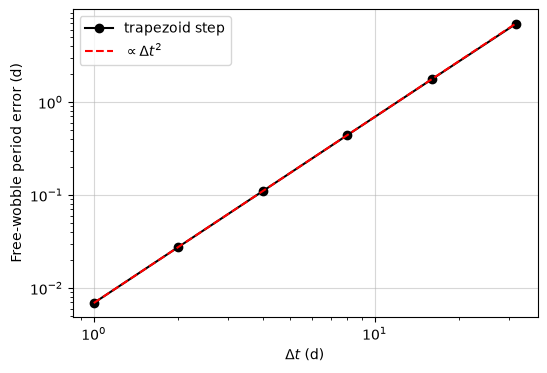

In [17]:
#=======================================================================
# Order of accuracy: discrete free-wobble period error against dt
#=======================================================================

dt_values = np.array([1.0, 2.0, 4.0, 8.0, 16.0, 32.0])
period_error = np.array([
    2 * np.pi / rc.per_day(rc.discrete_chandler_frequency(constants, k_ocean, dt), constants) - t_cw_ocean
    for dt in dt_values
])
slopes = np.diff(np.log(period_error)) / np.diff(np.log(dt_values))
print("period error (d):", np.array2string(period_error, precision=4))
print("log-log slopes:  ", np.array2string(slopes, precision=3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(dt_values, period_error, "ko-", label="trapezoid step")
ax.loglog(dt_values, period_error[0] * (dt_values / dt_values[0]) ** 2, "r--", label=r"$\propto\Delta t^2$")
ax.set_xlabel(r"$\Delta t$ (d)")
ax.set_ylabel("Free-wobble period error (d)")
ax.legend()
ax.grid(True, alpha=0.5)
plt.show()